# Getting Started: Optimal Dike Upgrades under Non-Stationary Sea Level Rise

This notebook shows how to use the optimization toolkit of this repository in five steps. Three submodels are combined and solved by backward induction:

```
SeaLevelRiseModel  (source.sea_level_rise_model)  lattice of sea level rise states and transition probabilities
RiskModel          (source.risk_model)            expected annual flood loss of a dike
CostModel          (source.cost_model)            cost of every dike upgrade
        └─> backward_induction (source.decision_analysis) ─> optimal first decision + RewardsTable
```

The baseline models of the thesis are used with one change: the retention of the dike is fixed at $\tilde{\varphi} = 1$, i.e. an upgrade only pays for the added height (equivalent to cost model used in Jongejan et al. 2026). Since there is only one dike, no inflexible/flexible comparison is made.

Run the notebook from the repository root (see `README.md` for the setup).

In [9]:
import numpy as np

from source.cost_model import RetentionCostModel
from source.decision_analysis import (
    backward_induction,
    plot_cost_by_capacity,
    plot_optimal_decisions_along_trajectories,
)
from source.risk_model import StandardRiskModel
from source.sea_level_rise_model import DirectFitSeaLevelRiseModel, plot_lattice

## 1. Sea Level Rise Model

The direct fit model is fitted to the KNMI23 projections (a mixture of three SSP scenarios) and turned into a recombining lattice with decisions every 10 years.

Any other sea level rise model can be used in the same way: subclass `SeaLevelRiseModel` and implement `_build_lattice()`, which returns a `ForwardLattice` (see `build_direct_fit_lattice` for an example). `backward_induction` only uses the model's `.lattice`.

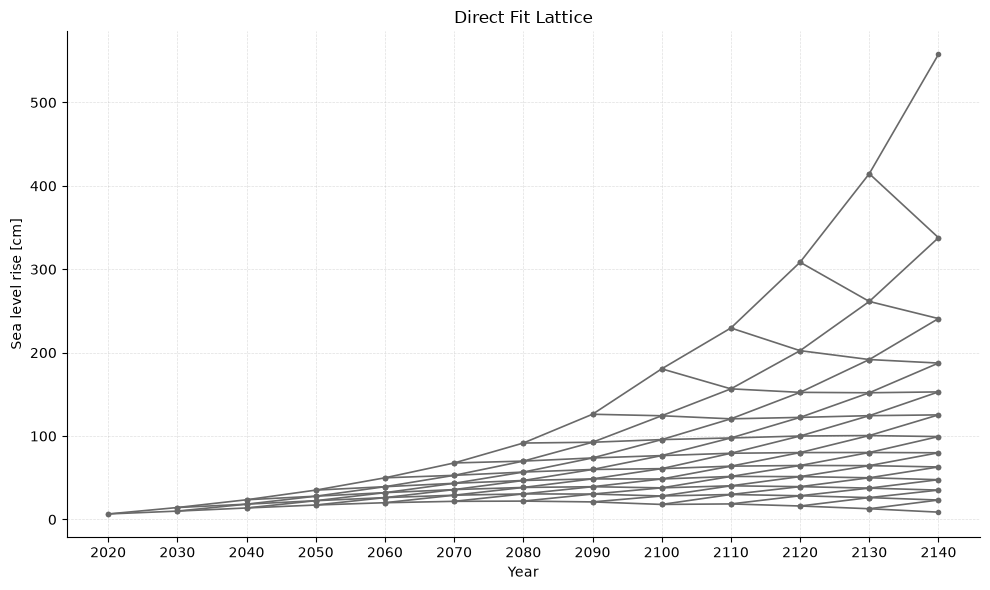

In [10]:
sea_level_rise_model = DirectFitSeaLevelRiseModel(
    start_year=2025,
    end_year=2150,
    step=10,  # Time between decisions [yr]
    method="mixture",  # Mixture of the SSP scenarios ...
    distribution=None,  # ... each fitted with a Pearson type IV distribution
    weights=[0.25, 0.5, 0.25],  # Scenario weights (SSP1-2.6, SSP2-4.5, SSP5-8.5)
    extrapolate=True,
    p=0.5,  # Transition probability of the lattice
)
_ = plot_lattice(sea_level_rise_model)

## 2. Risk and Cost Model

The risk model gives the expected annual flood loss of a dike with capacity $h$ at sea level rise $\theta$. The cost model prices an upgrade from $h_{i-1}$ to $h_i$ as $c + v \cdot (h_i - \tilde{\varphi}\, h_{i-1})$; with $\tilde{\varphi} = 1$ this is $c + v \cdot (h_i - h_{i-1})$. Fixing $\tilde{\varphi}$ to a single value (`phi_values=(1.0,)`) removes it from the optimization.

In [11]:
risk_model = StandardRiskModel(
    r=2.25,  # Scaling factor of sea level rise [-]
    a=0.0,  # Location of the extreme water level [m]
    b=1 / np.log(10),  # Scale of the extreme water level [m]
    D=10e9,  # Flood damage [€]
)

cost_model = RetentionCostModel(
    c=10e6,  # Fixed cost of an upgrade [€]
    v=60e6,  # Variable cost of an upgrade [€/m]
    phi_minus_1=1.0,  # Retention of the existing dike [-]
    phi_values=(1.0,),  # Retention of the new dike, fixed at 1 [-]
)

## 3. Optimization

`backward_kwargs` holds the parameters of the optimization itself. All heights are in meters (absolute), costs in euros. `backward_induction` returns the optimal first decision $(h_0, \tilde{\varphi}_0, \text{reward})$, where the reward is the negative expected discounted cost, and a `RewardsTable` with the expected reward of every first decision (`rewards.t0`) and the optimal later decisions (`rewards.rest`).

In [12]:
backward_kwargs = {
    "discount_rate": 0.0225,  # Annual discount rate [-]
    "h_minus_1": 2.0,  # Capacity of the existing dike [m]
    "max_possible_h": 10.0,  # Largest capacity considered above h_minus_1 [m]
    "h_step": 0.1,  # Height grid [m]
}

optimal_design, rewards = backward_induction(sea_level_rise_model, risk_model, cost_model, backward_kwargs)
h_0, phi_0, reward = optimal_design
print(f"Optimal initial capacity h_0 = {h_0 * 100:.0f} cm, expected cost {-reward / 1e6:.1f} M€")

Optimal initial capacity h_0 = 480 cm, expected cost 232.1 M€


## 4. Expected Cost by Initial Capacity

The expected cost of every first decision $h_0$, each followed by the optimal later upgrades. The circle marks the optimum.

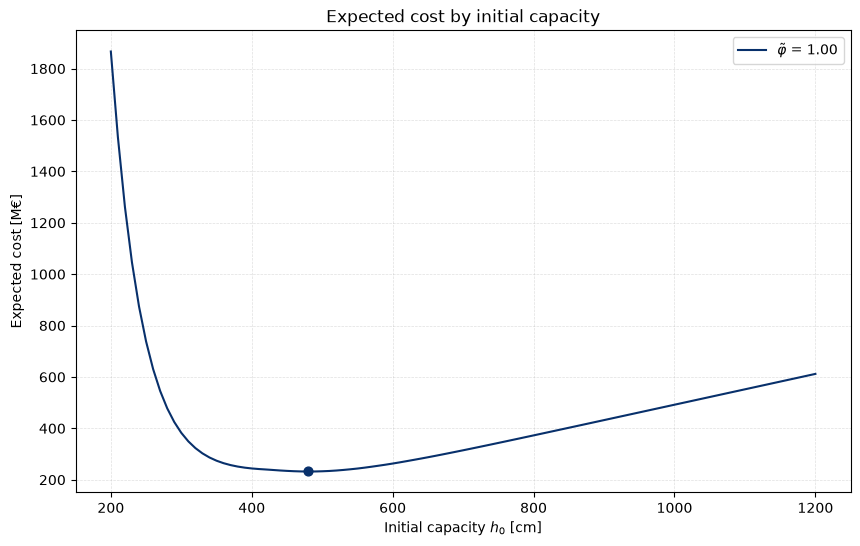

In [13]:
_ = plot_cost_by_capacity(rewards, flex_values=(1.0,), optimal=False)

## 5. Decisions along Sea Level Rise Trajectories

The optimal upgrades along two sampled trajectories (about the 9th and 98th percentile in 2150), drawn on the lattice. The table gives the realized cost along each trajectory and the number and mean size of the upgrades.

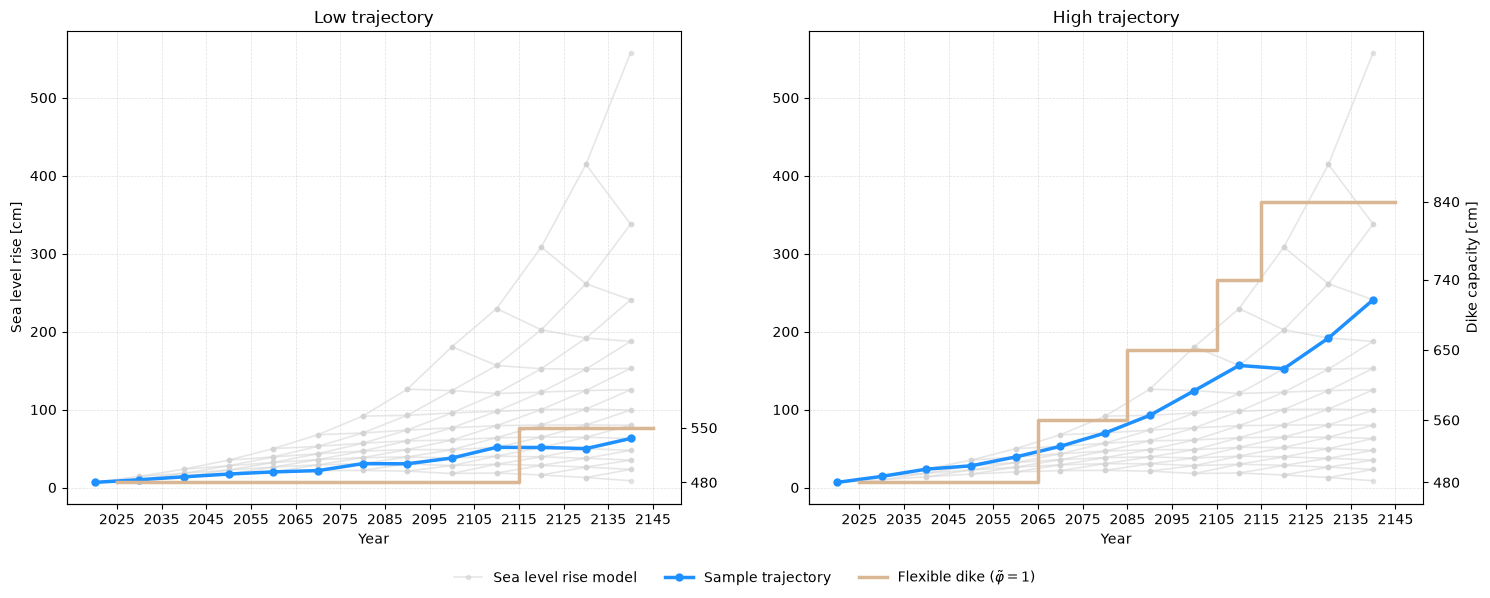

Design    h_0 [cm]    phi_0    E[cost] [M€]    Realized cost (Low trajectory) [M€]    Upgrades (Low trajectory)    Mean upgrade (Low trajectory) [cm]    Realized cost (High trajectory) [M€]    Upgrades (High trajectory)    Mean upgrade (High trajectory) [cm]
--------  ----------  -------  --------------  -------------------------------------  ---------------------------  ------------------------------------  --------------------------------------  ----------------------------  -------------------------------------
Flexible  480         1.00     232.1           206.9                                  2                            175                                   274.7                                   5                             128


In [14]:
trajectories = list(sea_level_rise_model.sample_trajectories(500, seed=42))
_ = plot_optimal_decisions_along_trajectories(
    rewards,
    {"Low trajectory": trajectories[26], "High trajectory": trajectories[202]},
    sea_level_rise_model,
    risk_model,
    cost_model,
    backward_kwargs,
    show_inflexible=False,  # Only one dike: no inflexible/flexible comparison
)

## Next Steps

- Replace `DirectFitSeaLevelRiseModel` by your own `SeaLevelRiseModel`; the steps above stay the same.
- Sensitivity to a parameter: `sweep_designs` (`source.decision_analysis`) solves the problem for several values of any model parameter or `backward_kwargs` entry.
- `Decision_Analysis.ipynb` reproduces all results of the thesis.